# CropGuard-Q : un vérificateur de cultures quantique mis à l'épreuve

**Moroccan Crop Classification Challenge · Qiskit Fall Fest · EMSI × Quantum Africa** — classer des champs des Doukkala en **luzerne, maïs ou blé** à partir de mesures Sentinel-2, et répondre à une question précise :

> **Ajouter un modèle quantique à un modèle classique apporte-t-il quelque chose, surtout quand les données sont falsifiées ou incomplètes, par rapport à l'ajout d'un autre modèle classique ?**

**Lancer le notebook** depuis la racine du dépôt (Python 3.12 comme épinglé ; testé aussi sous CPython 3.15) :

```bash
python3.12 -m venv .venv
.venv/bin/python -m pip install -r requirements.txt         # partie principale
.venv/bin/python -m pip install -r requirements-noise.txt   # optionnel : section 6 (étude du bruit)
.venv/bin/jupyter nbconvert --to notebook --execute --inplace notebooks/CropGuard_Q.ipynb
```

Les sections 1 à 4 donnent le **résultat principal** : simulation locale exacte, sans réseau, sans identifiants, sans paquet optionnel. Les sections 5 à 7 sont des **analyses complémentaires** ; chacune peut être désactivée dans la cellule suivante, et la section IBM ne fait que lire les résultats sauvegardés, sauf si `RUN_HARDWARE = True`. Chaque chiffre du texte est produit par les cellules (la section 8 est rédigée par `challenge/report.py`) ; chaque paramètre vient de `configs/experiment.json`, les faits sur les données de `data/manifest.json` et les réglages retenus de `configs/cropguard.json`. [`docs/GUIDE.md`](../docs/GUIDE.md) explique chaque fonction utilisée ici.

| Élément | Rôle |
|---|---|
| Inspecteur quantique | noyau de fidélité à feature map ZZ, un qubit par nombre PCA, vecteurs d'état exacts, puis un SVM à noyau précalculé |
| Inspecteurs classiques | SVM RBF et forêt aléatoire sur les mêmes nombres |
| Vote + alarme | étiquette majoritaire (le SVM RBF tranche si les trois diffèrent) ; un champ est **signalé** quand les trois ne sont pas unanimes |
| Contrôle apparié | le même pipeline, avec un SVM à noyau polynomial à la place du SVM quantique, réglé avec une grille de même taille |
| Correcteur IA | une régression linéaire qui ramène les valeurs de similarité bruitées vers les valeurs exactes ; utilisée pour le simulateur bruité et les runs IBM |

In [1]:
import contextlib, io, json, sys, time
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from challenge.config import EXPERIMENT, FEATURES, LABELS, MANIFEST, QUBITS
from challenge.data import load_data
from challenge.classical import reference
from challenge.metrics import score
from challenge.submission import Submission, MatchedControl, load_config, preprocessing
from challenge.kernel import QuantumKernelSVM
from challenge import guard, tune, mitigation, report, hardware_kernel as hk  # hardware_kernel n'importe le code IBM que s'il sert

RUN_TUNING = True       # ~1 min : relance la recherche de réglages ; le fichier gelé configs/cropguard.json sert dans tous les cas
RUN_ATTACK_LAB = True   # plusieurs minutes : falsification, étiquettes empoisonnées, bandes manquantes (analyse complémentaire)
RUN_NOISE_STUDY = True  # quelques minutes, demande requirements-noise.txt ; sinon l'étude sauvegardée est affichée
RUN_HARDWARE = False    # demande requirements-hardware.txt, QISKIT_IBM_TOKEN et une autorisation ; sinon les résultats sauvegardés sont affichés

OUT = ROOT / 'outputs'; (OUT / 'predictions').mkdir(parents=True, exist_ok=True)
L, SEEDS = list(LABELS), EXPERIMENT['seeds']
plt.rcParams.update({'figure.dpi': 110, 'font.size': 9, 'axes.grid': True, 'grid.alpha': .3})
def save_show(fig, name):
    fig.savefig(OUT / f'{name}.png', dpi=150, bbox_inches='tight'); plt.show()
def timed(fn):
    t = time.perf_counter(); out = fn(); return out, time.perf_counter() - t
T0 = time.perf_counter()

tables, _, manifest, _ = load_data()  # vérifie chaque empreinte, le schéma et le découpage avant tout
X, y = tables['train'][FEATURES].to_numpy(), tables['train'].target.to_numpy()
Xv, yv = tables['validation'][FEATURES].to_numpy(), tables['validation'].target.to_numpy()
Xt = tables['test'][FEATURES].to_numpy()  # mesures de test seulement : aucune étiquette de test n'existe dans ce dépôt
ids_v, ids_t = tables['validation'].sample_id.to_numpy(), tables['test'].sample_id.to_numpy()
print('Python', sys.version.split()[0], '| lignes', MANIFEST['rows'], '| image satellite', MANIFEST['observation_date'],
      '| relevé terrain', MANIFEST['survey_date_range'], '| qubits', QUBITS, '| entrées', FEATURES)

Python 3.15.2 | lignes {'train': 914, 'validation': 150, 'test': 221} | image satellite 2024-04-25 | relevé terrain ['2024-04-23', '2024-04-27'] | qubits 8 | entrées ['B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B9', 'B11', 'B12', 'NDVI']


In [2]:
# Affichage des tableaux : étiquettes en français, virgule décimale et grille complète.
# La grille est écrite en styles en ligne : JupyterLab les garde même quand le notebook n'est pas « de confiance ».
# Seul l'affichage change : les fichiers outputs/*.json gardent leurs clés anglaises.
from html import escape
from IPython.display import HTML

FR = {**report.NOMS,
    'RBF SVM alone': 'SVM RBF seul', '+ quantum SVM': '+ SVM quantique', '+ poly SVM': '+ SVM polynomial', '+ forest': '+ forêt',
    'quantum committee alarm': 'alarme du comité quantique', 'matched control alarm': 'alarme du contrôle apparié',
    'naive': 'naïf', 'adaptive': 'adaptatif',
    # noms d'axes
    'model': 'modèle', 'alarm': 'alarme', 'eps': 'ε', 'rate': 'taux', 'missing': 'bandes manquantes',
    'level': 'niveau de bruit', 'attack': 'attaque', 'first': 'premier',
    # métriques
    'macro_f1': 'macro-F1', 'accuracy': 'exactitude', 'flagged': 'signalés', 'undetected': 'non détectés',
    'accuracy_unflagged': 'exactitude (non signalés)', 'fit_seconds': 'entraînement (s)', 'predict_seconds': 'prédiction (s)',
    'mean': 'moyenne', 'sd': 'écart-type', 'delta': 'écart', 'ci95': 'IC 95 %', 'share_positive': 'part positive',
    # sections 1 et 2
    'explained variance': 'variance expliquée', 'stretch by 2nd scaler (vs PC1)': 'étirement par la 2e normalisation (vs PC1)',
    'frozen_settings': 'réglages gelés', 'tuning_seconds': 'durée du réglage (s)', 'best_validation_macro_f1': 'meilleur macro-F1 (validation)',
    # ressources
    'feature_map_depth': 'profondeur feature map', 'feature_map_cx': 'CX feature map', 'kernel_circuit_cx': 'CX circuit noyau',
    'trainable_quantum': 'paramètres quantiques entraînables', 'support_vectors': 'vecteurs de support',
    'training_states_simulated': 'états simulés (entraînement)', 'training_kernel_circuits': 'circuits noyau (entraînement)',
    'circuits_per_predicted_field': 'circuits par champ prédit', 'kernel_storage_bytes': 'stockage du noyau (octets)',
    'dual_coefficients': 'coefficients duaux', 'exact statevector': 'vecteur d’état exact', 'params': 'paramètres',
    'trees': 'arbres', 'total_nodes': 'nœuds au total', 'mean_depth': 'profondeur moyenne', 'stored_values': 'valeurs stockées',
    'nan': '—',
    # bruit et matériel IBM
    'device calibration used': 'calibration utilisée', 'device': 'processeur', 'retrieved_utc': 'relevée (UTC)',
    'two_qubit_gate': 'porte à 2 qubits', 'sx_error': 'erreur SX', 'sx_seconds': 'durée SX (s)', 'two_qubit_error': 'erreur 2 qubits',
    'two_qubit_seconds': 'durée 2 qubits (s)', 'readout_error': 'erreur de lecture', 't1_seconds': 'T1 (s)', 't2_seconds': 'T2 (s)',
    'mae_raw': 'erreur brute (MAE)', 'mae_zne': 'erreur ZNE (MAE)', 'mae_fixed': 'erreur corrigée (MAE)',
    'fixer_slope': 'pente du correcteur', 'fixer_intercept': 'ordonnée du correcteur',
    'f1_exact': 'F1 exact', 'f1_raw': 'F1 brut', 'f1_fixed': 'F1 corrigé', 'depth': 'profondeur', 'cx': 'CX',
    'max_dual': 'coef. dual max', 'exact_macro_f1': 'macro-F1 exact', 'agree_shot_noise': 'votes gardés (bruit de tir)',
    'agree_hardware_error': 'votes gardés (erreur QPU mesurée)',
    'backend': 'processeur', 'job_id': 'job ID', 'finished_utc': 'terminé (UTC)', 'quantum_params': 'paramètres quantiques',
    'shots': 'tirs', 'calibration_pairs': 'paires de calibration', 'transpiled_depth': 'profondeur transpilée',
    'transpiled_two_qubit_gates': 'portes 2 qubits transpilées', 'physical_qubits': 'qubits physiques', 'quantum_seconds': 'temps QPU (s)',
    'name': 'champ', 'target': 'culture réelle', 'quantum_exact': 'quantique (exact)',
    'quantum_hardware_raw': 'quantique (QPU brut)', 'quantum_hardware_fixed': 'quantique (QPU corrigé)',
}
FR |= {f'{m}_{c}': f'{w} {FR[c]}' for m, w in [('recall', 'rappel'), ('precision', 'précision')] for c in L}
eps_hw = EXPERIMENT['hardware']['tamper_eps']
FR |= {f'clean {c}': f'{FR[c]}, champ propre' for c in L}
FR |= {f'tampered {c} (eps {eps_hw})': f'{FR[c]}, champ falsifié (ε = {eps_hw})'.replace('.', ',') for c in L}

def fr(v):
    return FR.get(v, v) if isinstance(v, str) else v

def cell(v, digits):
    if isinstance(v, (list, tuple)): return '[' + ' ; '.join(str(cell(x, digits)) for x in v) + ']'
    if isinstance(v, (float, np.floating)):
        if np.isnan(v): return '—'
        return (f'{v:.3g}' if v != 0 and abs(v) < 10 ** -digits else f'{v:.{digits}f}').replace('.', ',')  # small values keep 3 digits
    return fr(v)

def head(v):
    return f'{v:g}'.replace('.', ',') if isinstance(v, (float, np.floating)) else fr(v)

def column(c, names):
    """One header line per column: levels joined with ' · ', a named numeric level as 'ε = 0,05'."""
    return ' · '.join(f'{fr(n)} = {head(v)}' if n else str(head(v)) for v, n in zip(c if isinstance(c, tuple) else (c,), names))

BORDER = 'border: 1px solid #b0b0b0; padding: 4px 10px; text-align: '

def show(df, digits=3):
    """Affiche un tableau en français, avec toutes les lignes de la grille et une seule ligne d'en-tête."""
    keep_index = not (isinstance(df.index, pd.RangeIndex) and df.index.name is None)  # 0, 1, 2 ... adds nothing
    th = lambda t: f'<th style="{BORDER}left">{escape(str(t))}</th>'
    td = lambda v: (f'<td style="{BORDER}{"right" if isinstance(v, (int, float, np.number, list)) and not isinstance(v, bool) else "left"}">'
                    f'{escape(str(cell(v, digits)))}</td>')
    top = [fr(n) or '' for n in df.index.names] * keep_index + [column(c, df.columns.names) for c in df.columns]
    body = [''.join(th(head(k)) for k in ((key if isinstance(key, tuple) else (key,)) if keep_index else ()))
            + ''.join(td(v) for v in row) for key, row in zip(df.index, df.itertuples(index=False))]
    display(HTML('<table style="border-collapse: collapse"><thead><tr>' + ''.join(th(t) for t in top) + '</tr></thead><tbody>'
                 + ''.join(f'<tr>{r}</tr>' for r in body) + '</tbody></table>'))

assert (cell(0.92144, 3), cell(np.nan, 3), cell(0.000301, 3), cell([-0.0194, 0.0238], 3)) == ('0,921', '—', '0,000301', '[-0,019 ; 0,024]')
assert column(('accuracy', 0.05), [None, 'eps']) == 'exactitude · ε = 0,05' and column('macro_f1', [None]) == 'macro-F1'

## 1. Entrées et prétraitement

Chaque modèle reçoit les mesures brutes listées dans `data/manifest.json` (jamais les identifiants ni les codes spatiaux). `Submission.fit` apprend `StandardScaler → PCA(qubits) → StandardScaler` sur les seules lignes d'entraînement, un nombre PCA par qubit ; avec 8 qubits, c'est la recette du fichier fourni `data/views/pca8.npz`, et la vérification ci-dessous confirme une correspondance exacte. Les dernières composantes portent très peu de variance, et la seconde normalisation les étire à l'unité ; la section 5 montre que c'est là que les attaques par falsification appuient.

In [3]:
prep = preprocessing().fit(X)
view_file = ROOT / f'data/views/pca{QUBITS}.npz'
if view_file.exists():
    view = np.load(view_file, allow_pickle=False)
    assert np.allclose(prep.transform(X), view['X_train']) and np.allclose(prep.transform(Xv), view['X_validation'])
    assert np.allclose(prep.transform(Xt), view['X_test'])
    print(f'identique au fichier fourni {view_file.name}')
pca = prep[1]
pca_table = pd.DataFrame({'explained variance': pca.explained_variance_ratio_.round(4),
                          'stretch by 2nd scaler (vs PC1)': np.sqrt(pca.explained_variance_[0] / pca.explained_variance_).round(1)},
                         index=[f'PC{i+1}' for i in range(QUBITS)]).T
show(pca_table, 4)

identique au fichier fourni pca8.npz


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8
variance expliquée,"0,5256","0,3714","0,0659","0,0283","0,0040","0,0019","0,0013","0,0010"
étirement par la 2e normalisation (vs PC1),"1,0000","1,2000","2,8000","4,3000","11,5000","16,8000","20,4000","22,8000"


## 2. Réglages : même budget pour tous, choisis sur la validation, puis gelés

Chaque inspecteur reçoit **une grille de même taille** (`configs/experiment.json`, `tuning.grids`), évaluée par le macro-F1 en validation ; en cas d'égalité, l'entrée la plus simple l'emporte ([`challenge/tune.py`](../challenge/tune.py)). Les gagnants sont gelés dans [`configs/cropguard.json`](../configs/cropguard.json) avant toute prédiction de test. Comme les mêmes champs de validation choisissent et évaluent les réglages, tous les chiffres de validation ci-dessous sont optimistes, autant pour le modèle quantique que pour ses contrôles.

Le noyau quantique a un réglage sensible, la **force de rotation** `scale`, qui multiplie les entrées avant qu'elles ne deviennent des angles. Une rotation trop forte rend chaque champ différent de tous les autres (effondrement du noyau).

la relance retrouve les réglages gelés : True


,réglages gelés,configurations,durée du réglage (s),meilleur macro-F1 (validation)
SVM quantique,"{'scale': 0.075, 'C': 100}",30,"4,1000","0,9200"
SVM polynomial,"{'degree': 3, 'coef0': 2, 'C': 1}",30,"1,6000","0,9269"
SVM RBF,"{'gamma': 0.06, 'C': 30}",30,"1,8000","0,9326"
forêt,"{'max_features': 2, 'min_samples_leaf': 2}",30,"43,2000","0,9130"


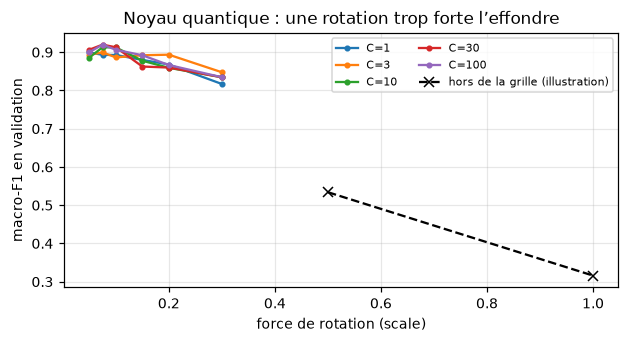

hors de la grille -> {0.5: 0.534, 1.0: 0.316}


In [4]:
config = load_config()
if RUN_TUNING:
    with contextlib.redirect_stdout(io.StringIO()):  # les lignes de progression de tune.py sont résumées dans le tableau ci-dessous
        rerun, log = tune.tune(write=False)
    print('la relance retrouve les réglages gelés :', all(rerun[k] == config[k] for k in tune.GRIDS))
else:
    log = json.loads((OUT / 'tuning_log.json').read_text())
show(pd.DataFrame({k: dict(frozen_settings=config[k], configurations=v['configurations'], tuning_seconds=round(v['seconds'], 1),
                              best_validation_macro_f1=round(v['best_validation_macro_f1'], 4)) for k, v in log.items()}).T, 4)

grid = pd.DataFrame(log['quantum']['rows'])
Z, Zv = prep.transform(X), prep.transform(Xv)
outside = {s: score(yv, QuantumKernelSVM(s, config['quantum']['C']).fit(Z, y).predict(Zv), L)['macro_f1']
           for s in EXPERIMENT['tuning']['illustration_scales']}
fig, ax = plt.subplots(figsize=(6.5, 3))
for C, g in grid.groupby('C'): ax.plot(g.scale, g.validation_macro_f1, marker='o', ms=3, label=f'C={C}')
ax.plot(list(outside), list(outside.values()), 'kx--', label='hors de la grille (illustration)')
ax.set(xlabel='force de rotation (scale)', ylabel='macro-F1 en validation', title='Noyau quantique : une rotation trop forte l’effondre')
ax.legend(fontsize=7, ncol=2); save_show(fig, 'cg_01_kernel_scale')
print('hors de la grille ->', {k: round(v, 3) for k, v in outside.items()})

## 3. Résultat principal : chaque graine en validation, puis prédictions de test gelées

Le SVM quantique, le SVM RBF et le SVM polynomial sont **déterministes** : leurs résultats se répètent d'une graine à l'autre ; seule la forêt (et donc les comités) dépend de la graine. Les durées comprennent le prétraitement, la simulation des vecteurs d'état, la construction du noyau et l'entraînement. La référence classique fournie est réentraînée et vérifiée contre `results/reference_0_predictions.csv`.

In [5]:
ref, ref_fit = timed(lambda: reference().fit(X, y))
ref_pred, ref_predict = timed(lambda: ref.predict(Xv))
supplied = pd.read_csv(ROOT / 'results/reference_0_predictions.csv').set_index('sample_id').loc[ids_v]
assert (supplied.prediction.to_numpy() == ref_pred).all(), 'refitted reference differs from the supplied run'

records, P, fitted = [], {}, {}
def record(name, seed, pred, **extra):
    P[name, seed] = pred
    records.append(dict(model=name, seed=seed, **score(yv, pred, L), **extra))
    pd.DataFrame({'sample_id': ids_v, 'target': yv, 'prediction': pred}).to_csv(
        OUT / 'predictions' / f"{name.replace(' ', '_')}_{seed}_validation.csv", index=False)

names = {'quantum': 'quantum SVM', 'poly': 'poly SVM', 'rbf': 'RBF SVM', 'forest': 'forest'}
for seed in SEEDS:
    record('reference', seed, ref_pred, fit_seconds=ref_fit, predict_seconds=ref_predict)
    for name, cls in [('quantum committee', Submission), ('matched control', MatchedControl)]:
        model, fit_s = timed(lambda: cls().fit(X, y, seed))
        ins, pred_s = timed(lambda: model.inspect(Xv))
        fitted[name, seed] = model
        record(name, seed, ins['prediction'], fit_seconds=fit_s, predict_seconds=pred_s, flagged=ins['flag'].mean(),
               accuracy_unflagged=(ins['prediction'] == yv)[~ins['flag']].mean())
        for member, votes in zip(model.names, ins['votes']):
            if (names[member], seed) not in P: record(names[member], seed, votes, fit_seconds=model.fit_seconds[member])
        test = model.inspect(Xt)  # réglages gelés, mesures de test seulement
        pd.DataFrame({'sample_id': ids_t, 'prediction': test['prediction'], 'flag': test['flag'],
                      **{m: v for m, v in zip(model.names, test['votes'])}}).to_csv(
            OUT / 'predictions' / f"{name.replace(' ', '_')}_{seed}_test.csv", index=False)

runs = pd.DataFrame(records)
order = ['quantum committee', 'matched control', 'reference', 'quantum SVM', 'poly SVM', 'RBF SVM', 'forest']
for k, c in enumerate(L):
    runs[f'recall_{c}'] = runs.recall.str[k]; runs[f'precision_{c}'] = runs.precision.str[k]
cols = ['macro_f1', 'accuracy'] + [f'recall_{c}' for c in L] + [f'precision_{c}' for c in L] + ['flagged', 'accuracy_unflagged', 'fit_seconds', 'predict_seconds']
summary = runs.groupby('model')[cols].agg(['mean', lambda s: s.std(ddof=0)]).rename(columns={'<lambda_0>': 'sd'}).loc[order]
show(summary[['macro_f1', 'accuracy', 'flagged', 'accuracy_unflagged', 'fit_seconds']], 4)
show(summary[[f'recall_{c}' for c in L] + [f'precision_{c}' for c in L]].xs('mean', axis=1, level=1), 3)

modèle,macro-F1 · moyenne,macro-F1 · écart-type,exactitude · moyenne,exactitude · écart-type,signalés · moyenne,signalés · écart-type,exactitude (non signalés) · moyenne,exactitude (non signalés) · écart-type,entraînement (s) · moyenne,entraînement (s) · écart-type
comité quantique,"0,9214","0,0033","0,9222","0,0031","0,0911","0,0031","0,9633","0,0001","1,3410","0,0909"
contrôle apparié,"0,9218","0,0032","0,9222","0,0031","0,0844","0,0031","0,9636","0,0001","1,2028","0,0922"
référence,"0,8797","0,0000","0,8800","0,0000",—,—,—,—,"0,0570","0,0000"
SVM quantique,"0,9200","0,0000","0,9200","0,0000",—,—,—,—,"0,1445","0,0154"
SVM polynomial,"0,9269","0,0000","0,9267","0,0000",—,—,—,—,"0,0379","0,0047"
SVM RBF,"0,9326","0,0000","0,9333","1,11e-16",—,—,—,—,"0,0343","0,0022"
forêt,"0,9040","0,0063","0,9044","0,0063",—,—,—,—,"1,1543","0,0806"


modèle,rappel luzerne,rappel maïs,rappel blé,précision luzerne,précision maïs,précision blé
comité quantique,"0,940","0,980","0,847","0,922","0,913","0,934"
contrôle apparié,"0,940","0,960","0,867","0,922","0,929","0,915"
référence,"0,940","0,860","0,840","0,887","0,915","0,840"
SVM quantique,"0,940","0,920","0,900","0,922","0,939","0,900"
SVM polynomial,"0,940","0,920","0,920","0,959","0,939","0,885"
SVM RBF,"0,960","0,980","0,860","0,941","0,925","0,935"
forêt,"0,933","0,933","0,847","0,921","0,909","0,882"


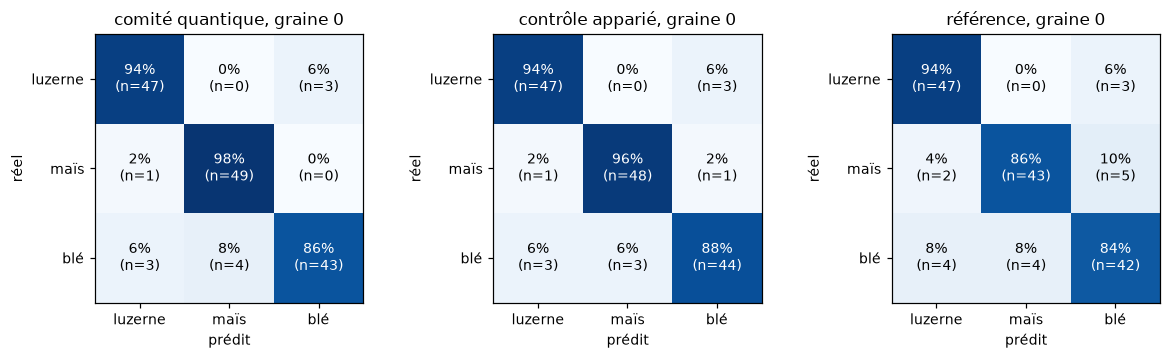

,qubits,profondeur feature map,CX feature map,CX circuit noyau,paramètres quantiques entraînables,vecteurs de support,états simulés (entraînement),circuits noyau (entraînement),circuits par champ prédit,stockage du noyau (octets),coefficients duaux,simulation,paramètres,valeurs stockées,arbres,nœuds au total,profondeur moyenne
comité quantique · SVM quantique,8,23,14,28,0,222,914,417241,222,6683168,444,vecteur d’état exact,"{'scale': 0.075, 'C': 100}",—,—,—,—
comité quantique · SVM RBF,—,—,—,—,—,200,—,—,—,—,—,—,"{'gamma': 0.06, 'C': 30}",2000,—,—,—
comité quantique · forêt,—,—,—,—,—,—,—,—,—,—,—,—,"{'max_features': 2, 'min_samples_leaf': 2}",—,300,40454,11.233333333333333
contrôle apparié · SVM polynomial,—,—,—,—,—,190,—,—,—,—,—,—,"{'degree': 3, 'coef0': 2, 'C': 1}",1900,—,—,—
contrôle apparié · SVM RBF,—,—,—,—,—,200,—,—,—,—,—,—,"{'gamma': 0.06, 'C': 30}",2000,—,—,—
contrôle apparié · forêt,—,—,—,—,—,—,—,—,—,—,—,—,"{'max_features': 2, 'min_samples_leaf': 2}",—,300,40454,11.233333333333333


**Ressources.** Le membre quantique utilise **8 qubits**, une feature map de profondeur 23 avec 14 portes CX (un circuit de noyau est la feature map suivie de son inverse : 28 CX avant compilation), **0 angle quantique entraînable** et 222 vecteurs de support. La simulation exacte calcule un vecteur d'état de 256 amplitudes par champ (914 pour l'entraînement) au lieu des 417 241 circuits compute-uncompute qu'un QPU demanderait pour le noyau d'entraînement ; prédire un champ sur un QPU demande 222 circuits, un par vecteur de support. Noyau d'entraînement : 6,7 Mo. Le prétraitement stocke 159 valeurs apprises. Comparer des nombres de paramètres n'a pas de sens pour des noyaux et des arbres : on rapporte donc les vecteurs de support, les valeurs stockées, les nœuds des arbres et le temps de calcul.

In [6]:
from sklearn.metrics import confusion_matrix
first = SEEDS[0]
fig, axes = plt.subplots(1, 3, figsize=(11, 3.3))
for ax, name in zip(axes, ['quantum committee', 'matched control', 'reference']):
    cm = confusion_matrix(yv, P[name, first], labels=L); norm = cm / cm.sum(1, keepdims=True)
    ax.imshow(norm, vmin=0, vmax=1, cmap='Blues'); ax.grid(False)
    for i in range(len(L)):
        for j in range(len(L)): ax.text(j, i, f'{norm[i, j]:.0%}\n(n={cm[i, j]})', ha='center', va='center', color='white' if norm[i, j] > .55 else 'black')
    ax.set(xticks=range(len(L)), yticks=range(len(L)), xticklabels=[fr(c) for c in L], yticklabels=[fr(c) for c in L], xlabel='prédit', ylabel='réel', title=f'{fr(name)}, graine {first}')
fig.tight_layout(); save_show(fig, 'cg_02_confusion')

res_q, res_c = fitted['quantum committee', first].resources(), fitted['matched control', first].resources()
resources = {'quantum committee': res_q, 'matched control': res_c,
             'reference': dict(support_vectors=int(ref[-1].n_support_.sum()), inputs=f'{len(FEATURES)} raw features',
                               params=json.loads((ROOT / 'configs/reference.json').read_text())['params'])}
show(pd.DataFrame({f'{c} · {fr(m)}': v for c, r in [('comité quantique', res_q), ('contrôle apparié', res_c)] for m, v in r['members'].items()}).T.astype(str))
display(Markdown(report.resources_text(res_q)))

## 4. Une différence est-elle réelle ? Bootstrap apparié par blocs spatiaux

Les deux modèles sont évalués sur les **mêmes blocs spatiaux de validation rééchantillonnés** (`data/validation_groups.json`), en moyennant les graines ; le nombre de rééchantillonnages et la graine viennent de `configs/experiment.json`. L'**écart** est le second modèle moins le premier ; un intervalle à 95 % qui contient 0 signifie que les données ne permettent pas de départager les deux.

In [7]:
W = guard.block_weights(ids_v)
stack = lambda name: np.array([P[name, s] for s in SEEDS])
pairs = [('matched control', 'quantum committee'), ('reference', 'quantum committee'), ('poly SVM', 'quantum SVM'),
         ('RBF SVM', 'quantum SVM'), ('RBF SVM', 'quantum committee')]
boot = pd.DataFrame([dict(first=a, second=b, **guard.paired_bootstrap(stack(a), stack(b), yv, W)) for a, b in pairs])
print(f"bootstrap apparié par blocs spatiaux, graine {EXPERIMENT['bootstrap']['seed']} |", len(np.unique(list(json.loads((ROOT / 'data/validation_groups.json').read_text()).values()))), 'blocs |', len(W), 'rééchantillonnages')
show(boot[['first', 'second', 'delta', 'ci95', 'share_positive']], 4)
main = dict(records=json.loads(runs.drop(columns=['precision', 'recall', 'support']).to_json(orient='records')),
            bootstrap=json.loads(boot.to_json(orient='records')), resources=resources, config=config,
            pca=json.loads(pca_table.to_json()), main_run_seconds=time.perf_counter() - T0)
(OUT / 'main_results.json').write_text(json.dumps(main, indent=2, default=str))
print(f"partie principale (sections 1 à 4) : {main['main_run_seconds']:.0f} s, relance optionnelle du réglage comprise")

bootstrap apparié par blocs spatiaux, graine 2026 | 18 blocs | 2000 rééchantillonnages


premier,second,écart,IC 95 %,part positive
contrôle apparié,comité quantique,"-0,0004","[-0,0194 ; 0,0238]","0,3780"
référence,comité quantique,"0,0416","[-0,0007 ; 0,0918]","0,9735"
SVM polynomial,SVM quantique,"-0,0069","[-0,0420 ; 0,0388]","0,3495"
SVM RBF,SVM quantique,"-0,0126","[-0,0419 ; 0,0277]","0,2330"
SVM RBF,comité quantique,"-0,0112","[-0,0320 ; 0,0053]","0,1175"


partie principale (sections 1 à 4) : 67 s, relance optionnelle du réglage comprise


## 5. Analyse complémentaire : le labo d'attaques et l'alarme

Toutes les attaques travaillent sur des **copies** ; le modèle soumis s'entraîne toujours sur les étiquettes propres publiées. Budgets, nombres d'étapes et tirages viennent de `configs/experiment.json` (`attack`).

* **Falsification** : on modifie les **mesures brutes** d'un champ de validation, pas les nombres PCA, et la modification traverse le prétraitement appris sur l'entraînement, comme le ferait un dossier truqué. Le budget `ε` est une norme L2 en écarts-types d'entraînement, et chaque bande reste dans la plage d'entraînement : un champ falsifié reste plausible. L'attaque est une recherche aléatoire sans gradient : un attaquant faible, donc les dégâts mesurés sont une borne inférieure.
  * attaquant **naïf** : trompe le SVM RBF, l'inspecteur classique principal commun aux deux comités, si bien que les deux comités voient des champs falsifiés *identiques*.
  * attaquant **adaptatif** : connaît les trois inspecteurs et fait baisser la plus grande de leurs marges.
* **Non détecté** = tous les inspecteurs de l'alarme s'accordent sur une mauvaise culture (l'alarme reste muette). Plus c'est bas, mieux c'est.
* **Étiquettes empoisonnées** : une part des étiquettes d'entraînement changée au hasard. **Bandes manquantes** : k bandes perdues par champ, remplacées par la moyenne d'entraînement.

In [8]:
if RUN_ATTACK_LAB:
    t = time.perf_counter()
    tamper_rows, tamper_fields = guard.tamper_study(X, y, Xv, yv)
    poison_rows = guard.poison_study(X, y, Xv, yv)
    missing_rows = guard.missing_study(fitted['quantum committee', first], fitted['matched control', first], X, Xv, yv)
    rate = lambda attack, eps, name: np.array([tamper_fields[attack, eps, s, name] for s in SEEDS])
    lab_boot = [dict(attack=atk, eps=e, first=a, second=b, **guard.paired_bootstrap(rate(atk, e, a), rate(atk, e, b), yv, W, stat='rate'))
                for atk, a, b in [('naive', '+ poly SVM', '+ quantum SVM'), ('naive', 'matched control', 'quantum committee'),
                                  ('adaptive', 'matched control', 'quantum committee')] for e in EXPERIMENT['attack']['eps']]
    lab = dict(tamper_rows=tamper_rows, poison_rows=poison_rows, missing_rows=missing_rows, bootstrap=lab_boot,
               seconds=time.perf_counter() - t)
    (OUT / 'attack_lab.json').write_text(json.dumps(lab, indent=1, default=float))
else:
    lab = json.loads((OUT / 'attack_lab.json').read_text())
print(f"labo d'attaques : {lab['seconds']:.0f} s")
tr = pd.DataFrame(lab['tamper_rows'])
alarms = ['RBF SVM alone', '+ quantum SVM', '+ poly SVM', '+ forest', 'quantum committee', 'matched control']
naive = tr[tr.attack.isin(['none', 'naive'])]
print('Non détectés (faux et unanimes), moyenne sur les graines ; ε = 0 : champs propres')
show(naive.pivot_table(index='alarm', columns='eps', values='undetected').loc[alarms])
print('Signalés à un humain')
show(naive.pivot_table(index='alarm', columns='eps', values='flagged').loc[alarms])
print('Exactitude de chaque inspecteur sur les champs falsifiés contre le SVM RBF (transfert)')
show(tr[tr.attack == 'naive transfer'].pivot_table(index='alarm', columns='eps', values='accuracy'))
print('Attaquant adaptatif (connaît les trois inspecteurs)')
show(tr[tr.attack == 'adaptive'].pivot_table(index='alarm', columns='eps', values=['undetected', 'flagged', 'accuracy']))

labo d'attaques : 346 s
Non détectés (faux et unanimes), moyenne sur les graines ; ε = 0 : champs propres


alarme,ε = 0,"ε = 0,05","ε = 0,1","ε = 0,2","ε = 0,5"
SVM RBF seul,"0,067","0,180","0,249","0,493","0,971"
+ SVM quantique,"0,040","0,109","0,187","0,358","0,784"
+ SVM polynomial,"0,040","0,140","0,218","0,400","0,887"
+ forêt,"0,051","0,136","0,153","0,196","0,313"
comité quantique,"0,033","0,089","0,127","0,182","0,264"
contrôle apparié,"0,033","0,124","0,147","0,187","0,307"


Signalés à un humain


alarme,ε = 0,"ε = 0,05","ε = 0,1","ε = 0,2","ε = 0,5"
SVM RBF seul,"0,000","0,000","0,000","0,000","0,000"
+ SVM quantique,"0,060","0,113","0,122","0,184","0,196"
+ SVM polynomial,"0,053","0,062","0,056","0,109","0,096"
+ forêt,"0,053","0,047","0,104","0,302","0,658"
comité quantique,"0,091","0,136","0,191","0,364","0,716"
contrôle apparié,"0,084","0,080","0,136","0,322","0,676"


Exactitude de chaque inspecteur sur les champs falsifiés contre le SVM RBF (transfert)


alarme,"ε = 0,05","ε = 0,1","ε = 0,2","ε = 0,5"
SVM RBF,"0,820","0,751","0,507","0,029"
forêt,"0,856","0,827","0,784","0,656"
SVM polynomial,"0,824","0,738","0,567","0,080"
SVM quantique,"0,842","0,738","0,549","0,116"


Attaquant adaptatif (connaît les trois inspecteurs)


alarme,"exactitude · ε = 0,05","exactitude · ε = 0,1","exactitude · ε = 0,2","exactitude · ε = 0,5","signalés · ε = 0,05","signalés · ε = 0,1","signalés · ε = 0,2","signalés · ε = 0,5","non détectés · ε = 0,05","non détectés · ε = 0,1","non détectés · ε = 0,2","non détectés · ε = 0,5"
contrôle apparié,"0,840","0,782","0,596","0,122","0,069","0,116","0,216","0,360","0,127","0,160","0,240","0,549"
comité quantique,"0,844","0,778","0,593","0,171","0,122","0,138","0,311","0,409","0,089","0,153","0,233","0,504"


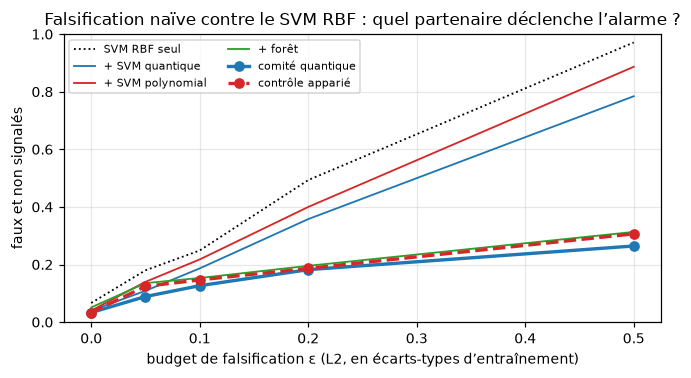

Bootstrap apparié du taux de non-détection (second moins premier ; négatif = le second en laisse passer moins)


attaque,ε,premier,second,écart,IC 95 %,part positive
naïf,"0,050",+ SVM polynomial,+ SVM quantique,"-0,031","[-0,094 ; 0,017]","0,100"
naïf,"0,100",+ SVM polynomial,+ SVM quantique,"-0,031","[-0,084 ; 0,016]","0,084"
naïf,"0,200",+ SVM polynomial,+ SVM quantique,"-0,042","[-0,132 ; 0,025]","0,114"
naïf,"0,500",+ SVM polynomial,+ SVM quantique,"-0,102","[-0,169 ; -0,046]","0,0005"
naïf,"0,050",contrôle apparié,comité quantique,"-0,036","[-0,086 ; 0,006]","0,043"
naïf,"0,100",contrôle apparié,comité quantique,"-0,020","[-0,050 ; -0,002]","0,000"
naïf,"0,200",contrôle apparié,comité quantique,"-0,004","[-0,016 ; 0,005]","0,135"
naïf,"0,500",contrôle apparié,comité quantique,"-0,042","[-0,094 ; -0,005]","0,011"
adaptatif,"0,050",contrôle apparié,comité quantique,"-0,038","[-0,091 ; 0,006]","0,029"
adaptatif,"0,100",contrôle apparié,comité quantique,"-0,007","[-0,025 ; 0,000]","0,000"


In [9]:
fig, ax = plt.subplots(figsize=(7, 3.4))
for name, style in zip(alarms, ['k:', 'C0-', 'C3-', 'C2-', 'C0-o', 'C3--o']):
    g = naive[naive.alarm == name].groupby('eps').undetected.mean()
    ax.plot(g.index, g.values, style, lw=2.2 if 'o' in style else 1.2, label=fr(name))
ax.set(xlabel='budget de falsification ε (L2, en écarts-types d’entraînement)', ylabel='faux et non signalés', ylim=(0, 1),
       title='Falsification naïve contre le SVM RBF : quel partenaire déclenche l’alarme ?')
ax.legend(fontsize=7, ncol=2); save_show(fig, 'cg_03_tamper_alarm')
print('Bootstrap apparié du taux de non-détection (second moins premier ; négatif = le second en laisse passer moins)')
show(pd.DataFrame(lab['bootstrap'])[['attack', 'eps', 'first', 'second', 'delta', 'ci95', 'share_positive']])

In [10]:
pr = pd.DataFrame(lab['poison_rows'])
print("Étiquettes d'entraînement empoisonnées : macro-F1 en validation, moyenne des tirages")
show(pr.pivot_table(index='model', columns='rate', values='macro_f1').loc[order[:2] + order[3:]])
mr = pd.DataFrame(lab['missing_rows'])
print('Bandes manquantes à la prédiction : macro-F1 et alarme, moyenne des tirages')
show(mr[mr.macro_f1.notna()].pivot_table(index='model', columns='missing', values='macro_f1').loc[order[:2] + order[3:]])
show(mr[mr.macro_f1.isna()].pivot_table(index='model', columns='missing', values=['flagged', 'undetected']))

Étiquettes d'entraînement empoisonnées : macro-F1 en validation, moyenne des tirages


modèle,"taux = 0,1","taux = 0,2","taux = 0,3"
comité quantique,"0,892","0,880","0,844"
contrôle apparié,"0,889","0,885","0,856"
SVM quantique,"0,862","0,829","0,783"
SVM polynomial,"0,878","0,878","0,845"
SVM RBF,"0,900","0,880","0,841"
forêt,"0,879","0,868","0,849"


Bandes manquantes à la prédiction : macro-F1 et alarme, moyenne des tirages


modèle,bandes manquantes = 1,bandes manquantes = 2,bandes manquantes = 4
comité quantique,"0,825","0,765","0,667"
contrôle apparié,"0,808","0,743","0,632"
SVM quantique,"0,752","0,671","0,564"
SVM polynomial,"0,775","0,696","0,572"
SVM RBF,"0,796","0,717","0,605"
forêt,"0,869","0,842","0,777"


modèle,signalés · bandes manquantes = 1,signalés · bandes manquantes = 2,signalés · bandes manquantes = 4,non détectés · bandes manquantes = 1,non détectés · bandes manquantes = 2,non détectés · bandes manquantes = 4
alarme du contrôle apparié,"0,219","0,307","0,431","0,059","0,064","0,085"
alarme du comité quantique,"0,270","0,383","0,519","0,056","0,057","0,067"


## 6. Analyse complémentaire : bruit quantique et correcteur IA (demande `qiskit-aer`)

Un vrai processeur renvoie des valeurs de similarité bruitées. Comme les circuits sont assez petits pour être simulés exactement, la vraie valeur de toute paire d'entraînement est connue : une **régression linéaire apprend bruité → exact** sur des paires de calibration et corrige des paires qu'elle n'a jamais vues. L'extrapolation à bruit nul (ZNE : chaque CX triplé, puis extrapolation vers un bruit nul) sert de méthode classique de référence ; elle coûte deux fois plus de circuits.

Le processeur simulé utilise les **vraies données de calibration** du QPU IBM nommé dans `configs/experiment.json` (`noise.device`) : erreurs et durées médianes des portes, erreur de lecture et T1/T2, lues en direct chez IBM (sauvegardées dans `outputs/device_profile.json`) ou, hors ligne, dans l'instantané de calibration publié par IBM pour ce processeur. Les niveaux 2× et 3× multiplient ces taux d'erreur.

,calibration utilisée
processeur,ibm_fez
relevée (UTC),2026-11-20T11:02:17+00:00
qubits,156
porte à 2 qubits,cz
erreur SX,"0,0003"
durée SX (s),"2,4e-08"
erreur 2 qubits,"0,0025"
durée 2 qubits (s),"6,8e-08"
erreur de lecture,"0,0104"
T1 (s),"0,0001"


niveau de bruit,erreur brute (MAE),erreur ZNE (MAE),erreur corrigée (MAE),pente du correcteur,ordonnée du correcteur,F1 exact,F1 brut,F1 corrigé,circuits,profondeur,CX
1,"0,0523","0,0318","0,0108","1,1967","-0,0002","0,6000","0,7209","0,7209",3380,51,28
2,"0,0956","0,0629","0,0129","1,4294","-0,0014","0,6000","0,7209","0,6351",3380,51,28
3,"0,1314","0,0943","0,0151","1,7052","-0,0025","0,6000","0,6645","0,6351",3380,51,28


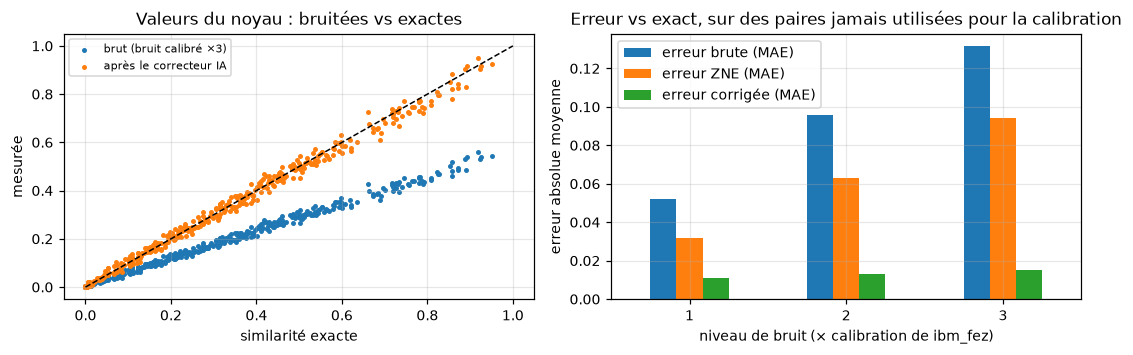

In [11]:
try:
    import qiskit_aer  # extra optionnel : requirements-noise.txt
    have_aer = True
except ImportError:
    have_aer = False
if RUN_NOISE_STUDY and have_aer:
    profile = mitigation.load_profile()
    q0 = fitted['quantum committee', first]
    noise, noise_s = timed(lambda: mitigation.noise_study(q0.members[0], q0.transform(X), y, q0.transform(Xv), yv, profile))
    noise['seconds'] = noise_s
    (OUT / 'noise_study.json').write_text(json.dumps(noise))
else:
    print("qiskit-aer absent ou étude désactivée : affichage de l'étude sauvegardée")
    noise = json.loads((OUT / 'noise_study.json').read_text())
show(pd.Series(noise['profile'], name='device calibration used').to_frame(), 4)
nr = pd.DataFrame(noise['rows']).set_index('level')
show(nr[['mae_raw', 'mae_zne', 'mae_fixed', 'fixer_slope', 'fixer_intercept', 'f1_exact', 'f1_raw', 'f1_fixed', 'circuits', 'depth', 'cx']], 4)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.3))
r = noise['rows'][-1]
axes[0].scatter(r['sample_exact'], r['sample_raw'], s=5, label=f"brut (bruit calibré ×{r['level']})")
axes[0].scatter(r['sample_exact'], r['sample_fixed'], s=5, label='après le correcteur IA')
axes[0].plot([0, 1], [0, 1], 'k--', lw=1); axes[0].set(xlabel='similarité exacte', ylabel='mesurée', title='Valeurs du noyau : bruitées vs exactes'); axes[0].legend(fontsize=7)
nr[['mae_raw', 'mae_zne', 'mae_fixed']].rename(columns=FR).plot.bar(ax=axes[1], rot=0)
axes[1].set(xlabel=f"niveau de bruit (× calibration de {noise['profile']['device']})", ylabel='erreur absolue moyenne',
            title='Erreur vs exact, sur des paires jamais utilisées pour la calibration')
fig.tight_layout(); save_show(fig, 'cg_04_noise_fixer')

## 7. Bonus matériel IBM : inférence seulement, comparée au simulateur exact

Le comité est entraîné en local puis gelé ; le QPU ne mesure que les circuits de similarité compute-uncompute entre quelques champs de validation et les vecteurs de support du SVM quantique. Rien n'est entraîné sur le matériel. Champs : un champ vérifié typique par culture, et un champ falsifié qui trompe le SVM RBF alors que le SVM quantique exact répond juste (l'alarme se déclenche donc). Des paires de calibration de champs d'entraînement voyagent dans le même job : le correcteur IA est ajusté **sur ce processeur, pendant cette session**. Le nombre de tirs, les paires de calibration et le budget de falsification viennent de `configs/experiment.json` (`hardware`). Le jeton est lu uniquement dans `QISKIT_IBM_TOKEN` ; il n'apparaît jamais dans ce notebook, dans les sorties ni dans git.

Le premier run utilise le modèle **soumis**. Une analyse hors ligne utilise ensuite les erreurs mesurées de ce run pour choisir un C adapté au matériel (le plus grand C qui garde au moins `hardware.min_vote_agreement` des votes), et un second run le vérifie. **Un petit exemple d'inférence par modèle, à modèle fixe, et non une estimation de l'exactitude.**

C,vecteurs de support,coef. dual max,macro-F1 exact,votes gardés (bruit de tir),votes gardés (erreur QPU mesurée)
"0,3",395,"0,300","0,893","0,993","0,985"
1,300,"1,000","0,893","0,978","0,969"
3,265,"3,000","0,900","0,934","0,891"
10,230,"10,000","0,913","0,810","0,721"
30,225,"30,000","0,920","0,628","0,566"
100,222,"100,000","0,920","0,490","0,432"


C prêt pour le matériel, selon la règle : 1
le run matériel sauvegardé utilisait C = 1 | la règle donne maintenant 1


,hardware_result.json,hardware_result_robust.json
processeur,ibm_fez,ibm_marrakesh
job ID,dc01nteq4uuc73a1tkq0,dc01qrts2omc7388k9h0
terminé (UTC),2026-11-20T10:11:03+00:00,2026-11-20T10:18:02+00:00
paramètres quantiques,"{'scale': 0.075, 'C': 100}","{'scale': 0.075, 'C': 1}"
tirs,512,512
circuits,928,1240
vecteurs de support,222,300
paires de calibration,40,40
profondeur transpilée,102,99
portes 2 qubits transpilées,26,26


,,champ,culture réelle,quantique (exact),quantique (QPU brut),quantique (QPU corrigé),SVM RBF,forêt
hardware_result.json,0,"luzerne, champ propre",luzerne,luzerne,luzerne,luzerne,luzerne,luzerne
hardware_result.json,1,"maïs, champ propre",maïs,maïs,luzerne,luzerne,maïs,maïs
hardware_result.json,2,"blé, champ propre",blé,blé,luzerne,luzerne,blé,blé
hardware_result.json,3,"blé, champ falsifié (ε = 0,1)",blé,blé,maïs,maïs,luzerne,luzerne
hardware_result_robust.json,0,"luzerne, champ propre",luzerne,luzerne,luzerne,luzerne,luzerne,luzerne
hardware_result_robust.json,1,"maïs, champ propre",maïs,maïs,maïs,maïs,maïs,maïs
hardware_result_robust.json,2,"blé, champ propre",blé,blé,blé,blé,blé,blé
hardware_result_robust.json,3,"blé, champ falsifié (ε = 0,1)",blé,blé,maïs,blé,maïs,maïs


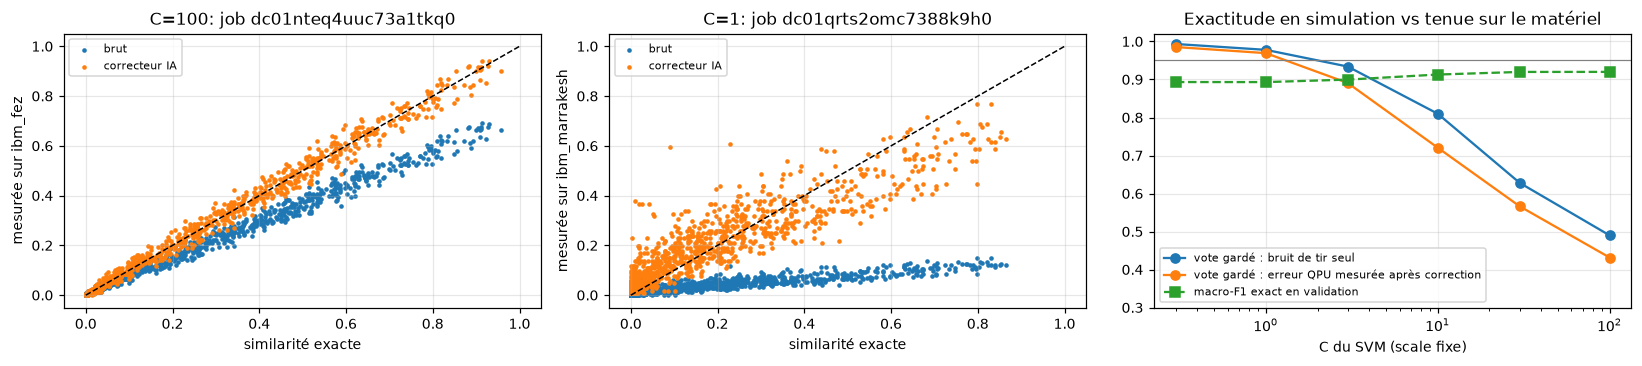

In [12]:
model0 = fitted['quantum committee', first]
if RUN_HARDWARE:
    backend = hk.connect()
    mitigation.save_profile(backend)  # met à jour la vraie calibration utilisée en section 6
    hk.run(model0, hk.pick_fields(model0, X, Xv, yv, ids_v), backend, approved=True, save=OUT / 'hardware_result.json')
hw = json.loads((OUT / 'hardware_result.json').read_text())

# Pourquoi les votes du modèle soumis peuvent-ils ne pas tenir sur le QPU ? Un grand C donne de grands coefficients duaux
# qui amplifient les erreurs du noyau. Hors ligne (sans QPU) : on rejoue les erreurs mesurées après correction, ou le bruit
# de tir, pour chaque C candidat.
scan = hk.robustness_scan(Z, y, Zv, yv, hk.residuals(hw), model0.members[0].scale)
chosen = hk.choose_C(scan)
(OUT / 'hardware_robustness.json').write_text(json.dumps(dict(rows=scan, chosen_C=chosen, source='hardware_result.json residuals after the AI error-fixer'), indent=1))
sc = pd.DataFrame(scan).set_index('C'); show(sc, 3)
print('C prêt pour le matériel, selon la règle :', chosen)

if RUN_HARDWARE and chosen is not None:
    cfg = load_config(); cfg['quantum'] = dict(cfg['quantum'], C=chosen)
    model1 = Submission(cfg).fit(X, y, first)
    hk.run(model1, hk.pick_fields(model1, X, Xv, yv, ids_v), backend, approved=True, save=OUT / 'hardware_result_robust.json')
runs_hw = {f: json.loads((OUT / f).read_text()) for f in ['hardware_result.json', 'hardware_result_robust.json'] if (OUT / f).exists()}
if 'hardware_result_robust.json' in runs_hw:
    print('le run matériel sauvegardé utilisait C =', runs_hw['hardware_result_robust.json']['quantum_params']['C'], '| la règle donne maintenant', chosen)

keys = ['backend', 'job_id', 'finished_utc', 'quantum_params', 'shots', 'circuits', 'support_vectors', 'calibration_pairs',
        'transpiled_depth', 'transpiled_two_qubit_gates', 'physical_qubits', 'quantum_seconds', 'mae_raw', 'mae_fixed', 'fixer_slope', 'fixer_intercept']
show(pd.DataFrame({f: {k: h.get(k) for k in keys} for f, h in runs_hw.items()}).astype(str))
show(pd.concat({f: pd.DataFrame(h['fields'])[['name', 'target', 'quantum_exact', 'quantum_hardware_raw', 'quantum_hardware_fixed', 'rbf', 'forest']]
                   for f, h in runs_hw.items()}))
fig, axes = plt.subplots(1, len(runs_hw) + 1, figsize=(5 * (len(runs_hw) + 1), 3.4))
for ax, (f, h) in zip(axes, runs_hw.items()):
    n = h['support_vectors'] * len(h['fields']); ex, me = np.array(h['exact']), np.array(h['measured'])
    ax.scatter(ex[:n], me[:n], s=4, label='brut')
    ax.scatter(ex[:n], np.clip(h['fixer_slope'] * me[:n] + h['fixer_intercept'], 0, 1), s=4, label='correcteur IA')
    ax.plot([0, 1], [0, 1], 'k--', lw=1); ax.legend(fontsize=7)
    ax.set(xlabel='similarité exacte', ylabel=f"mesurée sur {h['backend']}", title=f"C={h['quantum_params']['C']}: job {h['job_id']}")
ax = axes[-1]
ax.semilogx(sc.index, sc.agree_shot_noise, 'o-', label='vote gardé : bruit de tir seul')
ax.semilogx(sc.index, sc.agree_hardware_error, 'o-', label='vote gardé : erreur QPU mesurée après correction')
ax.semilogx(sc.index, sc.exact_macro_f1, 's--', label='macro-F1 exact en validation')
ax.axhline(EXPERIMENT['hardware']['min_vote_agreement'], color='grey', lw=.8)
ax.set(xlabel='C du SVM (scale fixe)', ylim=(0.3, 1.02), title='Exactitude en simulation vs tenue sur le matériel'); ax.legend(fontsize=7)
fig.tight_layout(); save_show(fig, 'cg_05_ibm_hardware')

## 8. Conclusions

La cellule suivante rédige les conclusions à partir des résultats ci-dessus avec [`challenge/report.py`](../challenge/report.py) : chaque chiffre et chaque verdict « détectable / non détectable » suit les données.

In [13]:
display(Markdown(report.findings(main=main, lab=lab, noise=noise, hw=hw, robust=runs_hw.get('hardware_result_robust.json'),
                                 scan=scan, chosen=chosen, runtime=time.perf_counter() - T0)))

**Réponse.** Sur données propres : aucune différence détectable entre le comité quantique et un comité classique réglé avec le même effort. Face à la falsification, le partenaire qui protège le plus est : forêt.

1. **Comparaison sur données propres (résultat principal).** Comité quantique 0,9214 ± 0,0033 en macro-F1 (92,2 % d'exactitude) contre 0,9218 ± 0,0032 pour le contrôle apparié ; bootstrap apparié -0,0004, intervalle à 95 % [-0,019 ; +0,024] : aucune différence détectable. Face à la référence fournie (0,8797), le comité quantique diffère de +0,042 [-0,001 ; +0,092] (l’intervalle contient zéro). Meilleur modèle seul : SVM RBF (0,933) ; comité quantique moins SVM RBF : -0,011 [-0,032 ; +0,005]. L'alarme signale 9,1 % des champs propres, et 96,3 % des champs non signalés sont bien classés.

2. **Falsification et alarme** (attaquant naïf qui vise le SVM RBF). À ε = 0,1, 24,9 % des champs passent inaperçus face au SVM RBF seul, 18,7 % avec un partenaire quantique, 21,8 % avec un partenaire polynomial, 15,3 % avec la forêt, 12,7 % face au comité quantique complet et 14,7 % face au contrôle apparié ; le comité quantique signale 19,1 % des champs contre 13,6 %. Bootstrap apparié, quantique moins contrôle : ε = 0,05 : -0,036 [-0,086 ; +0,006] ; ε = 0,1 : -0,020 [-0,050 ; -0,002] ; ε = 0,2 : -0,004 [-0,016 ; +0,005] ; ε = 0,5 : -0,042 [-0,094 ; -0,005] (2 intervalles sur 4 excluent zéro ; 12 comparaisons au total, donc chaque intervalle isolé se lit avec prudence). À ε = 0,2, le partenaire qui réduit le plus les passages inaperçus est : forêt (49,3 % → 19,6 % ; SVM quantique 35,8 %, SVM polynomial 40,0 %, forêt 19,6 %). Un attaquant qui connaît les trois inspecteurs fait passer 50,4 % (comité quantique) et 54,9 % (contrôle) des champs à ε = 0,5.

3. **Inspecteurs seuls.** Sur les champs falsifiés contre le SVM RBF (ε = 0,1), le SVM quantique garde 0,738 d'exactitude contre 0,738 pour le SVM polynomial. Avec 30,0 % d'étiquettes empoisonnées : SVM quantique 0,783 ; SVM polynomial 0,845 ; SVM RBF 0,841 ; forêt 0,849 (le plus bas : SVM quantique). Avec 4 bandes manquantes : SVM quantique 0,564 ; SVM polynomial 0,572 ; SVM RBF 0,605 ; forêt 0,777 (le plus bas : SVM quantique). Comités : 0,844 / 0,856 avec empoisonnement et 0,667 / 0,632 avec bandes manquantes (le comité quantique signale 51,9 % des champs contre 43,1 %). Description seulement : aucun bootstrap n'a été fait pour l'empoisonnement ni pour les bandes manquantes.

4. **Correcteur IA sur un processeur simulé à partir d'une vraie calibration** (ibm_fez, relevée le 2026-11-20T11:02:17+00:00 : erreur à deux qubits 0,25 %, à un qubit 0,03 %, de lecture 1 %, T1 130 µs, T2 95 µs). Erreur de similarité par rapport à la valeur exacte, brute → corrigée : 1× 0,052 → 0,011 (ZNE 0,032) ; 2× 0,096 → 0,013 (ZNE 0,063) ; 3× 0,131 → 0,015 (ZNE 0,094). Une seule droite, ajustée sur 200 paires de calibration ; la ZNE coûte deux fois plus de circuits. Le test de classification sur 30 champs est trop petit pour conclure quoi que ce soit sur l'exactitude. Vérification de réalisme : le modèle à calibration médiane prévoit une erreur brute de 0,052 à 1× ; le vrai run sur ibm_fez a mesuré 0,073 (autres paires de champs, et un vrai processeur ajoute des écarts entre qubits, de la diaphonie et de la dérive).

5. **Matériel IBM (inférence seulement).** `ibm_fez` (job `dc01nteq4uuc73a1tkq0`, modèle soumis, C = 100) : le correcteur, ajusté dans le même job, a fait passer l'erreur du noyau de 0,073 à 0,018 ; votes quantiques identiques au simulateur exact : 1 sur 4. Analyse hors ligne : le seul bruit de tir garde 49,0 % des votes de ce modèle (43,2 % sous l'erreur matérielle mesurée), car un grand C donne de grands poids duaux qui amplifient les erreurs du noyau. Règle : le plus grand C qui garde au moins 95,0 % des votes sous l'erreur mesurée → C = 1 (96,9 % ; macro-F1 exact 0,893 au lieu de 0,920). `ibm_marrakesh` (job `dc01qrts2omc7388k9h0`, C = 1) : votes identiques au simulateur : 4 sur 4. Sur le champ falsifié, le vote brut du processeur était faux (maïs) et le correcteur l'a rétabli (blé) : l'alarme s'est donc déclenchée sur un vrai processeur. Un petit exemple d'inférence par modèle, pas une estimation de l'exactitude.

6. **Effort de réglage.** SVM quantique : 30 configurations en 4,1 s ; SVM polynomial : 30 configurations en 1,6 s ; SVM RBF : 30 configurations en 1,8 s ; forêt : 30 configurations en 43,2 s (macro-F1 en validation ; `outputs/tuning_log.json`).

7. **Durée.** Partie principale 67 s ; notebook complet 619 s.

**Limites.** Les réglages ont été choisis et évalués sur les mêmes champs de validation. Les attaques sont une recherche faible, sans gradient, dans la plage d'entraînement ; le NDVI n'est pas maintenu cohérent avec B4/B8. L'étude du bruit utilise un processeur uniforme construit à partir de la calibration médiane, sur un petit sous-ensemble ; les vrais processeurs ajoutent des écarts entre qubits, de la diaphonie et de la dérive, donc le correcteur IA doit être recalibré à chaque session (ce que nous avons fait dans chaque job). Le correcteur a besoin de la simulation exacte pour ses étiquettes, ce qui ne marche que pour de petits circuits. Les résultats couvrent une région, une date et trois cultures.

**Nous ne prétendons pas** à un avantage quantique, quel qu'il soit ; ni que le modèle quantique serait plus robuste qu'un modèle classique ; ni que l'alarme arrête un attaquant qui connaît la défense ; ni que le correcteur IA améliore l'exactitude finale ; ni que les runs sur matériel mesurent l'exactitude.

**Code et méthodes réutilisés.** Le kit de départ des organisateurs (`challenge/data.py`, `classical.py`, `metrics.py`, `coverage.py` ; `metric_vector` réutilisé pour le bootstrap). `zz_feature_map` et `Statevector` de Qiskit (notre forme fermée est vérifiée contre eux dans `tests/`), scikit-learn, qiskit-aer, qiskit-ibm-runtime (calibration et exécution). Noyaux quantiques : Havlíček et al. 2019 ; ensembles classiques–quantiques : Grossi et al. 2022 ; bruit de tir et robustesse des SVM : Shastry et al. 2022 ; correction d'erreurs apprise : Czarnik et al. 2020, Liao et al. 2023 ; bonnes pratiques de benchmark : Bowles et al. 2024 ; attaques sur la télédétection : Czaja et al. 2018. Liens dans le README.

In [14]:
print(f'durée totale du notebook : {time.perf_counter() - T0:.0f} s')
print('sorties :', sorted(p.name for p in OUT.glob('*.json')), '| prédictions :', len(list((OUT / 'predictions').glob('*.csv'))), 'fichiers csv')

durée totale du notebook : 619 s
sorties : ['attack_lab.json', 'device_profile.json', 'hardware_result.json', 'hardware_result_robust.json', 'hardware_robustness.json', 'main_results.json', 'noise_study.json', 'tuning_log.json'] | prédictions : 27 fichiers csv
